# ДЗ 6.1 — Перенос импульса по кольцу (зелёный + жёлтый уровни)

Решаем линейное уравнение переноса в периодической области:

$$u_t + c\,u_x = 0,\qquad x\in[0,1),\quad c=1.$$

Точное решение — сдвиг начального профиля по кругу:
$$u(x,t)=u_0\big((x-ct)\bmod 1\big).$$

Один оборот занимает время $T=1$. На периодической сетке узел $x=1$ **не дублируем**: 
узлы $x_j = j\Delta x$, $j=0,\dots,N-1$, $\Delta x = 1/N$, и индекс $N$ замыкается на $0$.

Число Куранта: $C = c\,\Delta t/\Delta x$. При сгущении сетки сохраняем $C$ постоянным,
уменьшая $\Delta x$ и $\Delta t$ одновременно.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# ---------- точное решение ----------
def exact_solution(x, t, u0_func, c=1.0):
    return u0_func((x - c*t) % 1.0)

# ---------- начальные профили ----------
def u0_smooth(x):
    # зелёный уровень: 1 + 0.5 sin(2πx)
    return 1.0 + 0.5*np.sin(2*np.pi*x)

def u0_pulse(x):
    # жёлтый уровень: прямоугольный импульс 1 при 0.2 <= x < 0.4
    return np.where((x >= 0.2) & (x < 0.4), 1.0, 0.0)

# ---------- сетка ----------
def make_grid(N):
    dx = 1.0/N
    x = np.arange(N)*dx          # x = 0, dx, ..., 1-dx  (узел x=1 не дублируется)
    return x, dx

# ---------- интегрирование по времени с заданным C ----------
def integrate(scheme, u0_func, N, C, T_final):
    """
    scheme(u, C) -> u_new : один шаг схемы
    Возвращает историю: список (t, u) и финальное поле.
    """
    x, dx = make_grid(N)
    dt = C*dx                    # c = 1
    u = u0_func(x).copy()
    t = 0.0
    history = [(t, u.copy())]
    while t < T_final - 1e-14:
        dt_step = min(dt, T_final - t)   # подрезка последнего шага
        C_step = dt_step/dx              # эффективное число Куранта на последнем шаге
        u = scheme(u, C_step)
        t += dt_step
        history.append((t, u.copy()))
    return x, history

## Схема upwind

Для $c>0$ односторонняя разность назад:

$$u_j^{n+1} = u_j^n - C\,(u_j^n - u_{j-1}^n),\qquad C=\frac{c\Delta t}{\Delta x}.$$

Индексы периодические: $u_{-1} \equiv u_{N-1}$. Схема устойчива при $0<C\le 1$
и обладает **численной диффузией** порядка $O(\Delta x)$ — фронты размываются.

In [2]:
def upwind(u, C):
    # u_{j-1} с периодичностью
    u_prev = np.roll(u, 1)
    return u - C*(u - u_prev)

## Схема Лакса–Вендроффа

Второй порядок по пространству и времени (для гладких решений):

$$u_j^{n+1} = u_j^n - \frac{C}{2}(u_{j+1}^n - u_{j-1}^n)
+ \frac{C^2}{2}(u_{j+1}^n - 2u_j^n + u_{j-1}^n).$$

In [3]:
def lax_wendroff(u, C):
    u_next = np.roll(u, -1)   # u_{j+1}
    u_prev = np.roll(u, 1)    # u_{j-1}
    return u - 0.5*C*(u_next - u_prev) + 0.5*C**2*(u_next - 2*u + u_prev)

## Метрики

Средняя абсолютная ошибка и полное количество примеси:

$$E_1 = \Delta x\sum_j |u_j - u(x_j,t)|,\qquad
M = \Delta x\sum_j u_j.$$

In [4]:
def E1(u_num, u_exact, dx):
    return dx*np.sum(np.abs(u_num - u_exact))

def total_mass(u, dx):
    return dx*np.sum(u)

## Зелёный уровень — гладкий синус

$u_0(x)=1+\tfrac12\sin(2\pi x)$, $C=0.8$, сетки $N=50,100,200$.

Сравниваем upwind и Лакс–Вендрофф с точным решением после **1 оборота** ($t=1$)
и **5 оборотов** ($t=5$). Считаем $E_1$ и $M$.

N=  50, 1 оборот    : E1(up)=2.454e-02, E1(LW)=1.912e-03, M(up)=1.000000, M(LW)=1.000000
N=  50, 5 оборотов  : E1(up)=1.041e-01, E1(LW)=9.475e-03, M(up)=1.000000, M(LW)=1.000000
N= 100, 1 оборот    : E1(up)=1.232e-02, E1(LW)=4.737e-04, M(up)=1.000000, M(LW)=1.000000
N= 100, 5 оборотов  : E1(up)=5.702e-02, E1(LW)=2.368e-03, M(up)=1.000000, M(LW)=1.000000
N= 200, 1 оборот    : E1(up)=6.222e-03, E1(LW)=1.184e-04, M(up)=1.000000, M(LW)=1.000000
N= 200, 5 оборотов  : E1(up)=2.992e-02, E1(LW)=5.921e-04, M(up)=1.000000, M(LW)=1.000000


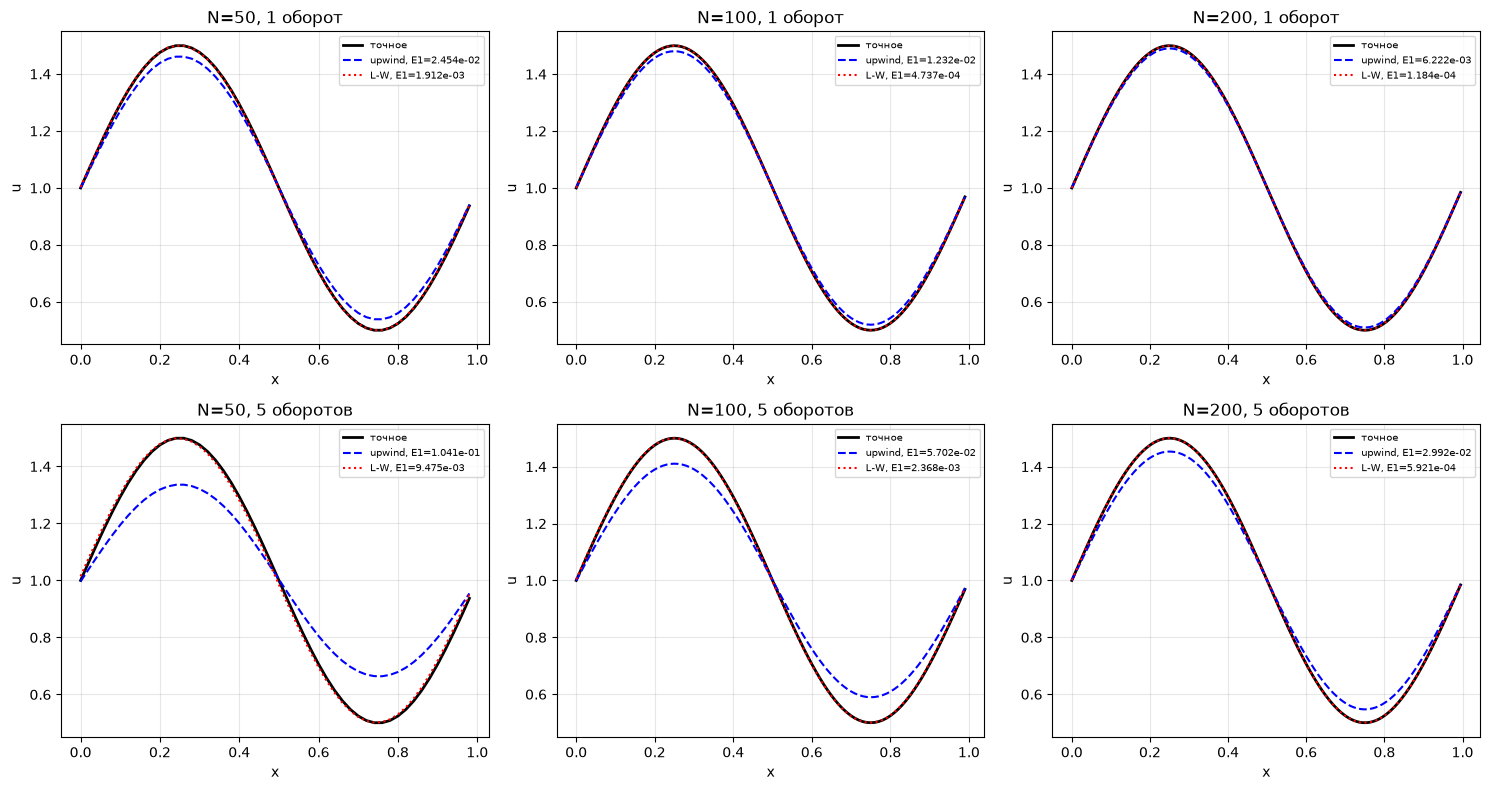

In [5]:
N_list = [50, 100, 200]
C = 0.8

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for col, N in enumerate(N_list):
    for row, (T_final, label) in enumerate([(1.0, "1 оборот"), (5.0, "5 оборотов")]):
        x, dx = make_grid(N)
        u_ex = exact_solution(x, T_final, u0_smooth)

        _, hist_up = integrate(upwind, u0_smooth, N, C, T_final)
        _, hist_lw = integrate(lax_wendroff, u0_smooth, N, C, T_final)
        u_up = hist_up[-1][1]
        u_lw = hist_lw[-1][1]

        e_up = E1(u_up, u_ex, dx)
        e_lw = E1(u_lw, u_ex, dx)
        m_up = total_mass(u_up, dx)
        m_lw = total_mass(u_lw, dx)

        ax = axes[row, col]
        ax.plot(x, u_ex, 'k-', lw=2, label='точное')
        ax.plot(x, u_up, 'b--', label=f'upwind, E1={e_up:.3e}')
        ax.plot(x, u_lw, 'r:',  label=f'L-W, E1={e_lw:.3e}')
        ax.set_title(f"N={N}, {label}")
        ax.set_xlabel("x"); ax.set_ylabel("u")
        ax.legend(fontsize=7)
        ax.grid(alpha=0.3)
        print(f"N={N:4d}, {label:12s}: E1(up)={e_up:.3e}, E1(LW)={e_lw:.3e}, "
              f"M(up)={m_up:.6f}, M(LW)={m_lw:.6f}")
plt.tight_layout(); plt.show()

## Сходимость ошибки от шага сетки

Строим $E_1$ в зависимости от $N$ в лог–лог масштабе. Ожидаем:
- upwind: порядок ~1 (первый порядок, но с диффузией);
- Лакс–Вендрофф: порядок ~2 на гладком решении.

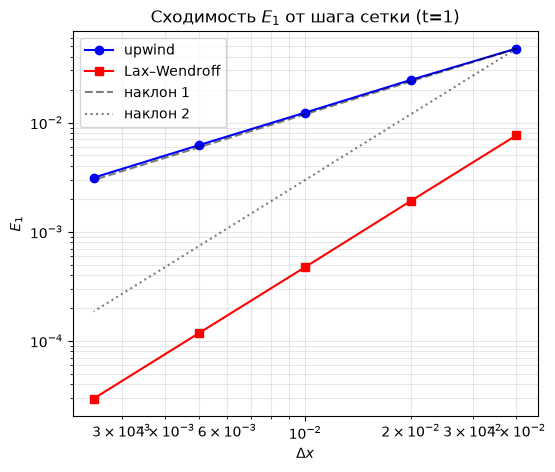

In [6]:
N_list = [25, 50, 100, 200, 400]
C = 0.8
T_final = 1.0

errs_up, errs_lw, dxs = [], [], []
for N in N_list:
    x, dx = make_grid(N)
    u_ex = exact_solution(x, T_final, u0_smooth)
    _, h_up = integrate(upwind, u0_smooth, N, C, T_final)
    _, h_lw = integrate(lax_wendroff, u0_smooth, N, C, T_final)
    errs_up.append(E1(h_up[-1][1], u_ex, dx))
    errs_lw.append(E1(h_lw[-1][1], u_ex, dx))
    dxs.append(dx)

dxs = np.array(dxs)
plt.figure(figsize=(6,5))
plt.loglog(dxs, errs_up, 'bo-', label='upwind')
plt.loglog(dxs, errs_lw, 'rs-', label='Lax–Wendroff')
# наклон опорных линий
for p, ls in [(1, '--'), (2, ':')]:
    plt.loglog(dxs, dxs**p * errs_up[0]/dxs[0]**p, 'k'+ls, alpha=0.5,
               label=f'наклон {p}')
plt.xlabel(r"$\Delta x$"); plt.ylabel(r"$E_1$")
plt.title("Сходимость $E_1$ от шага сетки (t=1)")
plt.legend(); plt.grid(True, which='both', alpha=0.3)
plt.show()

## Масса во времени

Показываем, что $M(t)$ для обеих схем практически постоянна (консервативность
в периодической области), хотя распределение при этом искажается. Это и есть
ответ на вопрос задания: **сохранение количества примеси не означает, что
распределение найдено правильно**.

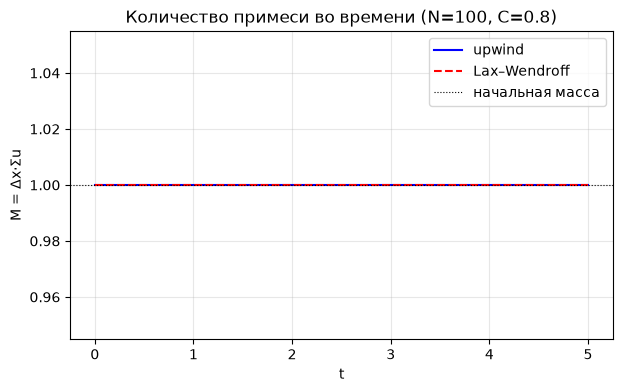

max |M(t) - M(0)| upwind     : 4.440892098500626e-16
max |M(t) - M(0)| Lax–Wendroff: 4.440892098500626e-16


In [7]:
N = 100; C = 0.8; T_final = 5.0
x, dx = make_grid(N)

_, h_up = integrate(upwind, u0_smooth, N, C, T_final)
_, h_lw = integrate(lax_wendroff, u0_smooth, N, C, T_final)

t_up = np.array([h[0] for h in h_up])
t_lw = np.array([h[0] for h in h_lw])
M_up = np.array([total_mass(h[1], dx) for h in h_up])
M_lw = np.array([total_mass(h[1], dx) for h in h_lw])

plt.figure(figsize=(7,4))
plt.plot(t_up, M_up, 'b-', label='upwind')
plt.plot(t_lw, M_lw, 'r--', label='Lax–Wendroff')
plt.axhline(M_up[0], color='k', lw=0.8, ls=':', label='начальная масса')
plt.xlabel("t"); plt.ylabel("M = Δx·Σu")
plt.title("Количество примеси во времени (N=100, C=0.8)")
plt.legend(); plt.grid(alpha=0.3); plt.show()

print("max |M(t) - M(0)| upwind     :", np.max(np.abs(M_up - M_up[0])))
print("max |M(t) - M(0)| Lax–Wendroff:", np.max(np.abs(M_lw - M_lw[0])))

### Ответ на вопрос: означает ли сохранение количества примеси, что её распределение найдено правильно?

**Нет, не означает.** 

Результаты показывают, что обе схемы (и upwind, и Лакс-Вендрофф) сохраняют интегральное количество примеси $M$ с точностью до машинной погрешности (около $10^{-16}$) на протяжении всех 5 оборотов. Это происходит потому, что обе схемы являются консервативными (в периодической области поток через левую границу ячейки равен потоку через правую границу соседней).

Однако **распределение (форма профиля) при этом сильно искажается**:
- Схема upwind из-за сильной численной диффузии "размазывает" профиль, уменьшая амплитуду максимумов и минимумов. Ошибка $E_1$ падает только с первым порядком ($O(\Delta x)$).
- Схема Лакса-Вендроффа из-за дисперсии дает паразитные осцилляции, хотя в целом точнее удерживает форму ($O(\Delta x^2)$).

Таким образом, сохранение интеграла (массы) — это лишь необходимое, но **не достаточное** условие правильности численного решения. Схема может идеально сохранять массу, но "размазать" сигнал до неузнаваемости (что и демонстрирует upwind при N=50 на 5 оборотах).

## Жёлтый уровень - Прямоугольный импульс

$u_0(x)=1$ при $0.2\le x<0.4$, иначе $0$. 

Сравниваем upwind и Лакс–Вендрофф
при $C=0.5,\,0.8,\,1.0$ после одного оборота ($t=1$). **Не обрезаем**
отрицательные значения и выбросы $>1$ — именно они показывают дисперсию L-W
и диффузию upwind.

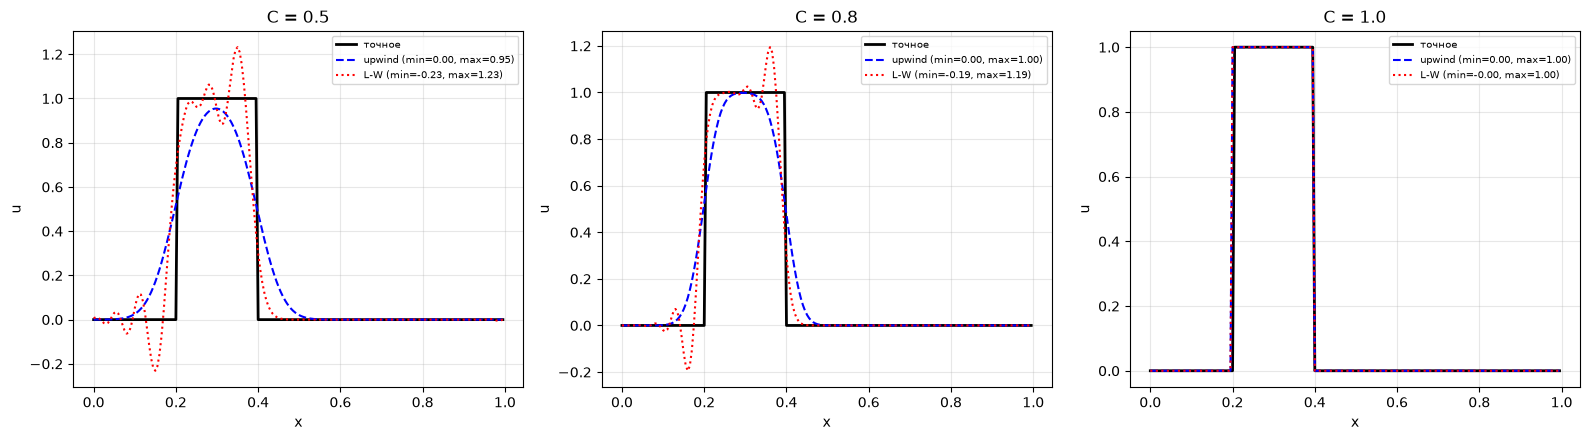

In [8]:
N = 200
C_values = [0.5, 0.8, 1.0]
T_final = 1.0

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, C in zip(axes, C_values):
    x, dx = make_grid(N)
    u_ex = exact_solution(x, T_final, u0_pulse)
    _, h_up = integrate(upwind, u0_pulse, N, C, T_final)
    _, h_lw = integrate(lax_wendroff, u0_pulse, N, C, T_final)
    u_up, u_lw = h_up[-1][1], h_lw[-1][1]

    ax.plot(x, u_ex, 'k-', lw=2, label='точное')
    ax.plot(x, u_up, 'b--', label=f'upwind (min={u_up.min():.2f}, max={u_up.max():.2f})')
    ax.plot(x, u_lw, 'r:',  label=f'L-W (min={u_lw.min():.2f}, max={u_lw.max():.2f})')
    ax.set_title(f"C = {C}")
    ax.set_xlabel("x"); ax.set_ylabel("u")
    ax.legend(fontsize=7); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

## Крупный план фронтов

Увеличенные фрагменты левого и правого фронтов при одинаковых масштабах осей.

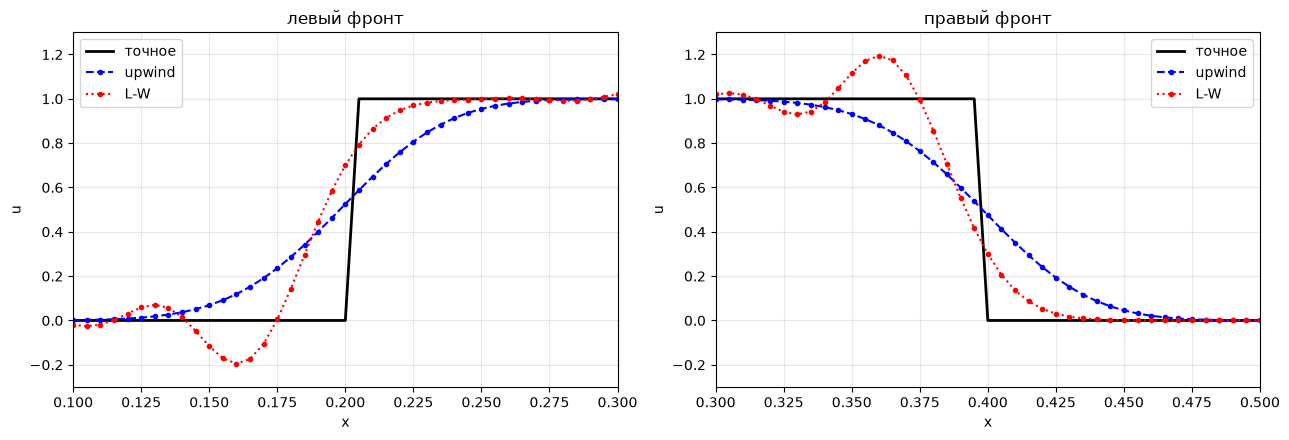

In [9]:
N = 200; C = 0.8; T_final = 1.0
x, dx = make_grid(N)
u_ex = exact_solution(x, T_final, u0_pulse)
_, h_up = integrate(upwind, u0_pulse, N, C, T_final)
_, h_lw = integrate(lax_wendroff, u0_pulse, N, C, T_final)
u_up, u_lw = h_up[-1][1], h_lw[-1][1]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
# левый фронт около x = 0.2 + t = 0.2 + 1 = 1.2 -> mod 1 = 0.2
for ax, (lo, hi, title) in zip(axes, [(0.10, 0.30, "левый фронт"),
                                       (0.30, 0.50, "правый фронт")]):
    mask = (x >= lo) & (x <= hi)
    ax.plot(x[mask], u_ex[mask], 'k-', lw=2, label='точное')
    ax.plot(x[mask], u_up[mask], 'b--o', ms=3, label='upwind')
    ax.plot(x[mask], u_lw[mask], 'r:o',  ms=3, label='L-W')
    ax.set_xlim(lo, hi); ax.set_ylim(-0.3, 1.3)
    ax.set_title(title); ax.set_xlabel("x"); ax.set_ylabel("u")
    ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

## Неустойчивость при $C=1.1$

Условие CFL: $C\le 1$. При $C=1.1$ обе схемы формально неустойчивы.

Upwind теряет монотонность (коэффициент $1-C<0$), Лакс–Вендрофф — тем более.

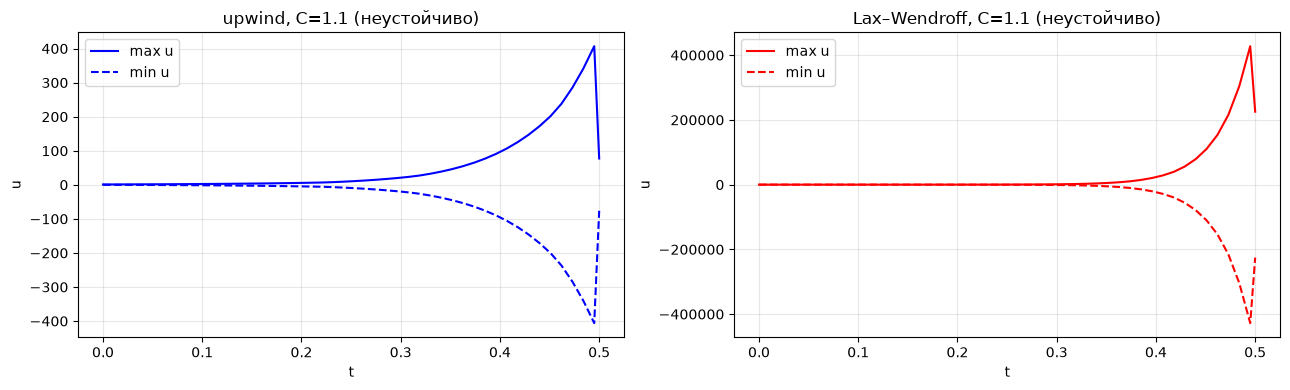

upwind     : max u = 77.20368750417126  min u = -76.20368748896365
L-W        : max u = 225338.66760620484  min u = -225336.55678177538


In [10]:
N = 100; C = 1.1; T_final = 0.5
x, dx = make_grid(N)

_, h_up = integrate(upwind, u0_pulse, N, C, T_final)
_, h_lw = integrate(lax_wendroff, u0_pulse, N, C, T_final)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, hist, name, color in [(axes[0], h_up, "upwind", 'b'),
                              (axes[1], h_lw, "Lax–Wendroff", 'r')]:
    t_arr = np.array([h[0] for h in hist])
    umax = np.array([h[1].max() for h in hist])
    umin = np.array([h[1].min() for h in hist])
    ax.plot(t_arr, umax, color=color, label='max u')
    ax.plot(t_arr, umin, color=color, ls='--', label='min u')
    ax.set_title(f"{name}, C={C} (неустойчиво)")
    ax.set_xlabel("t"); ax.set_ylabel("u")
    ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

print("upwind     : max u =", h_up[-1][1].max(), " min u =", h_up[-1][1].min())
print("L-W        : max u =", h_lw[-1][1].max(), " min u =", h_lw[-1][1].min())

## Минимум, максимум и $E_1$ во времени

Строим для $C=0.5,0.8,1.0,1.1$ эволюцию $\min u$, $\max u$ и $E_1(t)$.

Устойчивые расчёты ($C\le1$) отделены от неустойчивого ($C=1.1$): у последнего
амплитуда растёт, $E_1$ взрывается.

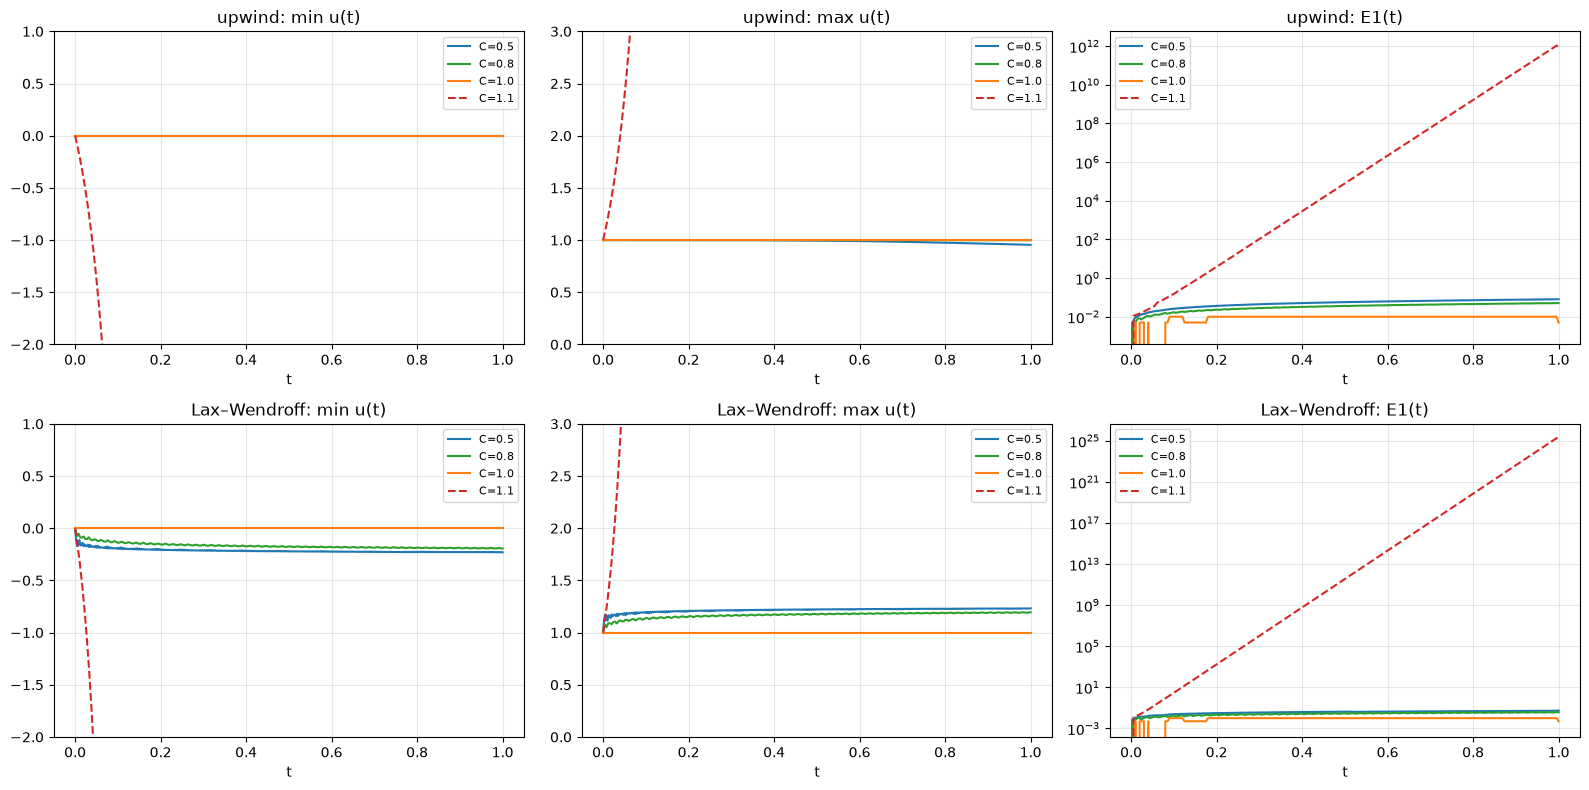

In [11]:
N = 200
T_final = 1.0
C_values = [0.5, 0.8, 1.0, 1.1]
colors = {0.5: 'tab:blue', 0.8: 'tab:green', 1.0: 'tab:orange', 1.1: 'tab:red'}

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for C in C_values:
    x, dx = make_grid(N)
    for scheme, name, row in [(upwind, "upwind", 0), (lax_wendroff, "L-W", 1)]:
        _, hist = integrate(scheme, u0_pulse, N, C, T_final)
        t_arr = np.array([h[0] for h in hist])
        umin = np.array([h[1].min() for h in hist])
        umax = np.array([h[1].max() for h in hist])
        uex = [exact_solution(x, tt, u0_pulse) for tt in t_arr]
        err = np.array([E1(h[1], e, dx) for h, e in zip(hist, uex)])

        ls = '--' if C > 1 else '-'
        axes[row, 0].plot(t_arr, umin, ls, color=colors[C], label=f"C={C}")
        axes[row, 1].plot(t_arr, umax, ls, color=colors[C], label=f"C={C}")
        axes[row, 2].plot(t_arr, err,  ls, color=colors[C], label=f"C={C}")

for row, name in enumerate(["upwind", "Lax–Wendroff"]):
    axes[row,0].set_title(f"{name}: min u(t)"); axes[row,0].set_ylim(-2, 1)
    axes[row,1].set_title(f"{name}: max u(t)"); axes[row,1].set_ylim(0, 3)
    axes[row,2].set_title(f"{name}: E1(t)")
    axes[row,2].set_yscale('log')
    for j in range(3):
        axes[row,j].set_xlabel("t"); axes[row,j].grid(alpha=0.3)
        axes[row,j].legend(fontsize=8)
plt.tight_layout(); plt.show()

## Анимация переноса прямоугольного импульса

Анимация с наложением точного решения и двух численных (upwind и L-W) при $C=0.8$.

Видно: upwind «размазывает» импульс, L-W даёт осцилляции у фронтов.

In [12]:
from matplotlib.animation import FuncAnimation
from IPython.display import HTML

N = 200; C = 0.8; T_final = 1.0
x, dx = make_grid(N)

# сохраняем историю с шагом по времени
_, h_up = integrate(upwind, u0_pulse, N, C, T_final)
_, h_lw = integrate(lax_wendroff, u0_pulse, N, C, T_final)
n_frames = min(len(h_up), len(h_lw))
idx = np.linspace(0, n_frames-1, 60).astype(int)   # ~60 кадров

fig, ax = plt.subplots(figsize=(8, 4))
line_ex, = ax.plot([], [], 'k-', lw=2, label='точное')
line_up, = ax.plot([], [], 'b--', label='upwind')
line_lw, = ax.plot([], [], 'r:',  label='L-W')
ax.set_xlim(0, 1); ax.set_ylim(-0.4, 1.6)
ax.set_xlabel("x"); ax.set_ylabel("u"); ax.legend(); ax.grid(alpha=0.3)
title = ax.set_title("")

def update(frame):
    i = idx[frame]
    t = h_up[i][0]
    line_ex.set_data(x, exact_solution(x, t, u0_pulse))
    line_up.set_data(x, h_up[i][1])
    line_lw.set_data(x, h_lw[i][1])
    title.set_text(f"t = {t:.3f}")
    return line_ex, line_up, line_lw, title

anim = FuncAnimation(fig, update, frames=len(idx), interval=60, blit=True)
plt.close(fig)
HTML(anim.to_jshtml())

### Ответы на вопросы (Жёлтый уровень)

**1. Почему схема, более точная на гладком профиле, может давать нефизические значения на разрыве?**

Схема Лакса–Вендроффа имеет второй порядок точности, что делает её великолепной для гладких функций. Однако она не обладает свойством монотонности (в ней нет ограничителей потока). Согласно теореме Годунова, линейная схема выше первого порядка точности не может быть монотонной. Из-за дисперсии на резких перепадах (разрывах) L-W порождает паразитные осцилляции (эффект Гиббса), из-за чего концентрация может становиться отрицательной или превышать максимальное начальное значение. Схема upwind, будучи первого порядка, сильно размазывает разрыв (диффузия), но остается монотонной.

**2. Почему случай $C=1$ требует отдельного рассмотрения?**

При числе Куранта $C = c \Delta t / \Delta x = 1$ (что совпадает с условием CFL) численные схемы вырождаются в точный сдвиг на один узел сетки. Это связано с тем, что за один шаг по времени характеристика проходит ровно одно расстояние между узлами $\Delta x$. И upwind, и Лакс–Вендрофф при $C=1$ дают идеально точное решение для прямоугольного импульса (без размытия и осцилляций), так как ошибка аппроксимации в этом частном случае обнуляется.

**3. Вывод по сгущению сетки и устойчивости:**

При нарушении условия CFL ($C=1.1$) решение экспоненциально нарастает, что делает расчет бессмысленным. Для устойчивых расчетов ($C \le 1$) сгущение сетки уменьшает ошибку $E_1$.